# Python

In [184]:
import numpy as np
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os

## Visualizing polymers in a 3D lattice

#### Importing full lattice state

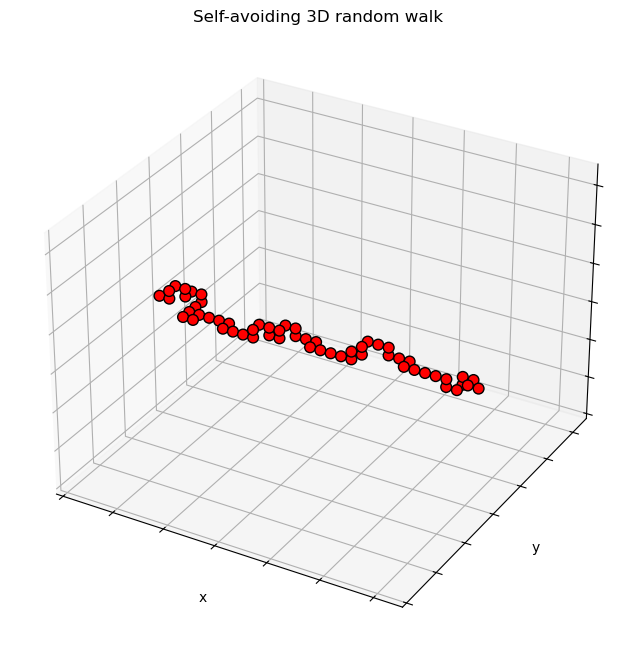

In [20]:
# import json data
dirname = "20251024/testpoly_frame10" 
# dirname = "20250924/testpoly" 
lattice = json.load(open("data/"+dirname+".json"))
lattice = np.array(lattice)

# Get coordinates where array == 1
coords1 = np.argwhere(lattice[..., -1] == 1)
coords2 = np.argwhere(lattice[..., -2] == 1)
x1, y1, z1 = coords1[:, 2], coords1[:, 1], coords1[:, 0]
x2, y2, z2 = coords2[:, 2], coords2[:, 1], coords2[:, 0]

# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
# ax.scatter(x1, y1, z1, s=40, c='blue', marker='o', alpha=0.5)
ax.scatter(x2, y2, z2, s=60, c='red', marker='o', edgecolor="black", alpha=1)

# ax.scatter(4,7,8, s=80, c='black', marker='o', alpha=1)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')
plt.show()

#### Importing species coordinates

In [295]:
dirname = "20251203/test_frame2"
labels = True
project = True

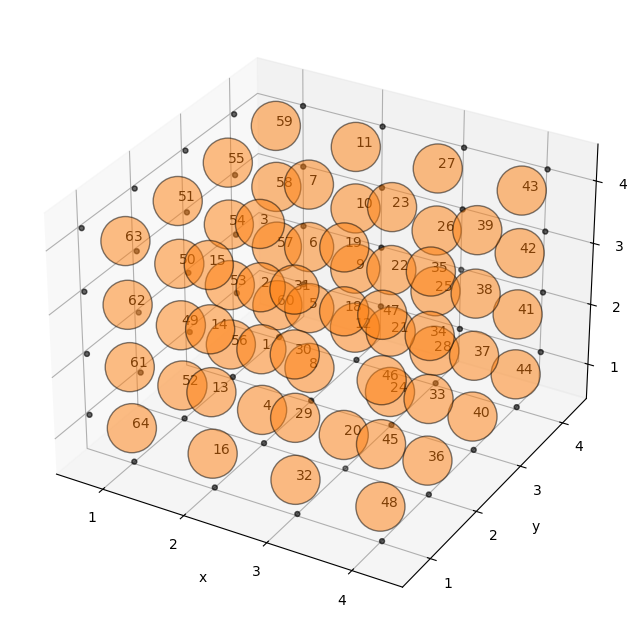

In [296]:
# import json data

slist = json.load(open("data/"+dirname+".json"))
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
L = int(slist["1"]["boxlength"])

for key, val in slist.items():
    arr = np.array(val["coords"])
    l = None

    if len(arr) == 4:
        x, y, z, l = arr
    else:
        x, y, z = arr
    
    # if val["name"][:4] == "poly":
    #     ax.scatter(x-0.5, y-0.5, z-0.5, s=60, c='red', 
    #                marker='o', edgecolor="black", alpha=1)

    # if val["name"][-1] == "a":
    #     ax.scatter(x-0.5, y-0.5, z-0.5, s=5000/L, color = 'C0', 
    #                marker='o', edgecolor="black", alpha=0.5)
        
        if project:
            # projections
            ax.scatter(x-0.45, y-0.55, 0, s=50, color = 'black', 
                        marker='.', edgecolor="black", alpha=0.2)
            ax.scatter(x-0.45, L, z-0.45, s=50, color = 'black', 
                        marker='.', edgecolor="black", alpha=0.2)
            ax.scatter(0, y-0.55, z-0.45, s=50, color = 'black', 
                        marker='.', edgecolor="black", alpha=0.2)
        
    # if val["name"][-1] == "b":
    #     ax.scatter(x-0.5, y-0.5, z-0.5, s=5000/L, color = 'C1', 
    #                marker='o', edgecolor="black", alpha=0.5)

    if val["name"][:4] == "bulk":
        ax.scatter(x-0.5, y-0.5, z-0.5, s=5000/L, color = 'C1', 
                   marker='o', edgecolor="black", alpha=0.5)
        
        if project:
            # projections
            ax.scatter(x-0.45, y-0.55, 0, s=50, color = 'black', 
                        marker='.', edgecolor="black", alpha=0.2)
            ax.scatter(x-0.45, L, z-0.45, s=50, color = 'black', 
                        marker='.', edgecolor="black", alpha=0.2)
            ax.scatter(0, y-0.55, z-0.45, s=50, color = 'black', 
                        marker='.', edgecolor="black", alpha=0.2)
        
    if l is not None and labels:
        for k in range(len(x)):
            ax.text(x[k]-0.5, y[k]-0.5, z[k]-0.5, l[k], size=10)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, slist["1"]["boxlength"])
ax.set_ylim(0, slist["1"]["boxlength"])
ax.set_zlim(0, slist["1"]["boxlength"])

# Generalized ticks based on lattice size
# Use boxlength as lattice size (integer number of sites per axis)
ticks = np.arange(0.5, L + 0.5, step=min(L, int(L/8)+1))
labels = np.arange(1, L + 1, step=min(L, int(L/8)+1))

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_yticks(ticks)
ax.set_yticklabels(labels)
ax.set_zticks(ticks)
ax.set_zticklabels(labels)
ax.grid(True, which="both")
plt.show()

## Phase transitions

#### Polymer

In [128]:
def plot_simulation_dashboard(res_or_path, keya, keyb, show=True, psize=30):
    """
    Plot acceptance rate, gyration radius, Hamiltonian, polymer length vs frames,
    and a 3D scatter of the final polymer configuration.

    res_or_path: dict or path to JSON file produced by the Julia simulation.
    """
    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            res = res_[str(keya)][str(keyb)]
    else:
        res = res_or_path[str(keya)][str(keyb)]

    # Safely extract arrays
    def to_np(key):
        arr = np.array(res.get(key, []))
        return arr
    
    print("Species name: ", res["species_name"])
    print("Interaction potential: ", res["alpha"])
    print("Chemical potential: ", res["beta"])

    gyr = to_np("gyration_radius")
    ham = to_np("hamiltonian")
    acc = to_np("acceptance_rate")

    if "polymer_length" in res.keys():
        plen = to_np("polymer_length")
    elif "length" in res.keys():
        plen = to_np("length") * np.ones(len(acc))

    n = max(len(gyr), len(plen), len(ham), len(acc))
    frames = np.arange(1, n + 1)

    fig = plt.figure(figsize=(7, 10))
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 2])

    # Time series
    ax_acc = fig.add_subplot(gs[0, 0])
    ax_gyr = fig.add_subplot(gs[0, 1])
    ax_ham = fig.add_subplot(gs[1, 1])
    ax_len = fig.add_subplot(gs[1, 0])

    if len(acc):
        ax_acc.plot(frames[1:len(acc)], acc[1:], color='C0')
    ax_acc.set_title('Acceptance rate')
    ax_acc.set_xlabel('Frame')
    ax_acc.set_ylabel('Rate')
    ax_acc.grid(True, alpha=0.3)
    ax_acc.set_xscale('log')

    if len(gyr):
        ax_gyr.plot(frames[1:len(gyr)], gyr[1:], color='C1')
    ax_gyr.set_title('Gyration radius')
    ax_gyr.set_xlabel('Frame')
    ax_gyr.set_ylabel('Radius')
    ax_gyr.grid(True, alpha=0.3)
    ax_gyr.set_xscale('log')

    if len(ham):
        ax_ham.plot(frames[1:len(ham)], ham[1:], color='C2')
    ax_ham.set_title('Hamiltonian')
    ax_ham.set_xlabel('Frame')
    ax_ham.set_ylabel('Energy')
    ax_ham.grid(True, alpha=0.3)
    ax_ham.set_xscale('log')

    if len(plen):
        ax_len.plot(frames[1:len(plen)], plen[1:], color='C3')
    ax_len.set_title('Polymer length')
    ax_len.set_xlabel('Frame')
    ax_len.set_ylabel('Length')
    ax_len.grid(True, alpha=0.3)
    ax_len.set_xscale('log')

    # 3D final configuration
    ax3d = fig.add_subplot(gs[2, :], projection='3d')
    x, y, z = res["final_coordinates"]
    
    ax3d.scatter(x, y, z, s=psize, c='red', marker='o', edgecolor='black', alpha=1)

    L = res.get('boxlength', None)
    if L is not None:
        ax3d.set_xlim(0, L)
        ax3d.set_ylim(0, L)
        ax3d.set_zlim(0, L)
    ax3d.set_title('Final polymer configuration')
    ax3d.set_xlabel('x')
    ax3d.set_ylabel('y')
    ax3d.set_zlabel('z')

    plt.tight_layout()
    if show:
        plt.show()
    return fig

Species name:  poly2
Interaction potential:  -0.75
Chemical potential:  1.0


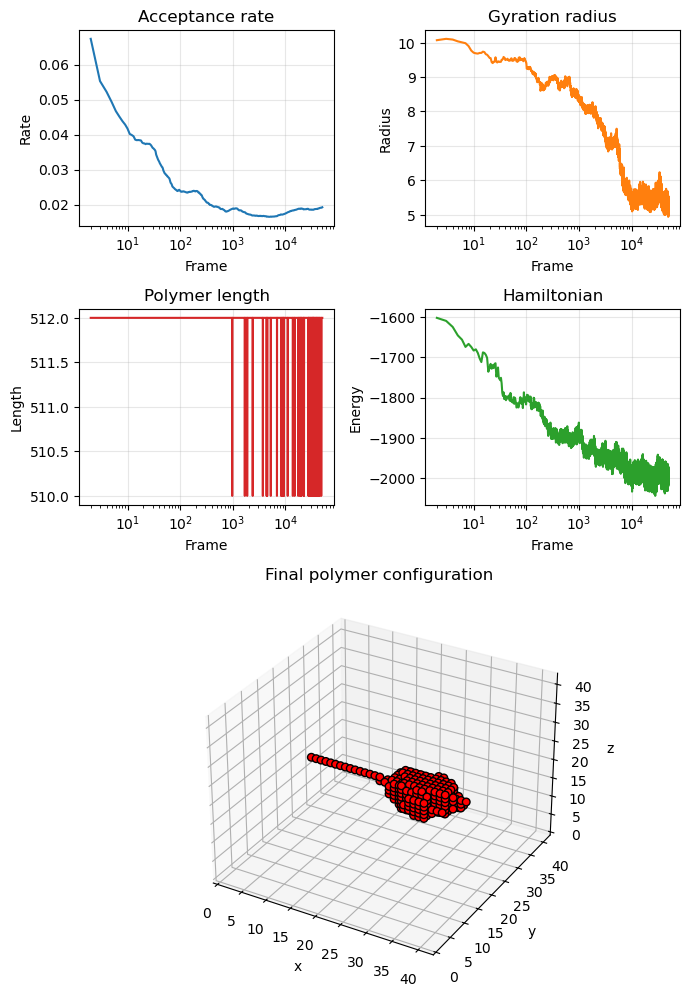

In [194]:
# Example usage:
alpha_index = 8
beta_index = 1
fig = plot_simulation_dashboard('data/20251101/radius_intpot_8h/radius_intpot_cpu{}.json'.format(alpha_index), 
                                alpha_index, beta_index)

In [192]:
out_dir = "media/figures"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "polymer_dashboard_8.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/polymer_dashboard_8.pdf


#### Phase transition with respect to interaction potential

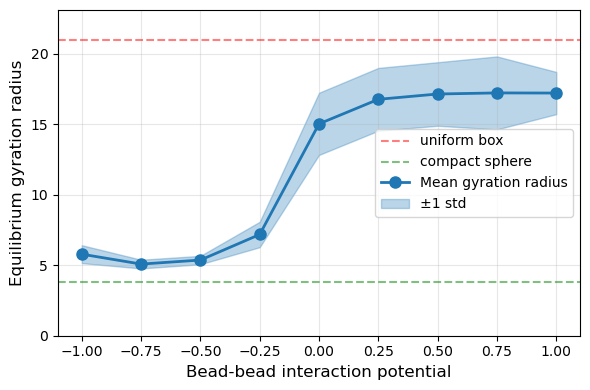

Interaction Potential → Mean Gyration Radius ± Std Dev:
  β = -1.00 → 5.784 ± 0.635 (n=35)
  β = -0.75 → 5.081 ± 0.309 (n=35)
  β = -0.50 → 5.366 ± 0.298 (n=35)
  β = -0.25 → 7.179 ± 0.901 (n=35)
  β =  0.00 → 15.026 ± 2.204 (n=35)
  β =  0.25 → 16.766 ± 2.226 (n=35)
  β =  0.50 → 17.142 ± 2.253 (n=35)
  β =  0.75 → 17.220 ± 2.587 (n=35)
  β =  1.00 → 17.210 ± 1.498 (n=35)


In [167]:
import glob
from collections import defaultdict

# Load all JSON files from the directory
def plot_order_param(data_dir, warmup=None, thinning=None):
    json_files = sorted(glob.glob(os.path.join(data_dir, "*.json")))

    # Dictionary to store gyration radii grouped by interaction potential
    alpha_to_gyr = defaultdict(list)

    # Read all files and extract final gyration radius and alpha values
    for json_file in json_files:
        with open(json_file, 'r') as f:
            data = json.load(f)
            # Iterate through all alpha and beta combinations in each file
            for alpha_key in data.keys():
                for beta_key in data[alpha_key].keys():
                    result = data[alpha_key][beta_key]
                    alpha = result.get("alpha", None)
                    gyr = result.get("gyration_radius", [])

                    if warmup is None:
                        warmup = int(result["nframes"]/5)
                    
                    if thinning is None:
                        thinning = int(result["nframes"]/5)
                    
                    if alpha is not None and len(gyr) > 0:
                        # Get samples of gyration radius at equilibrium
                        for i in range(5):
                            final_gyr = gyr[warmup+i*thinning-1]
                            alpha_to_gyr[alpha].append(final_gyr)

    # Calculate mean and std for each alpha value
    alphas = sorted(alpha_to_gyr.keys())
    means = [np.mean(alpha_to_gyr[b]) for b in alphas]
    stds = [np.std(alpha_to_gyr[b]) for b in alphas]

    # Create the plot
    fig, ax = plt.subplots(figsize=(6, 4))

    # Radius of compacted sphere
    if "maxlength" in result.keys():
        length = result["maxlength"]
    elif "length" in result.keys():
        length = result["length"]
        
    boxlength = result["boxlength"]
    radius = (3*length/(4*np.pi))**(1/3)
    Rg_sphere = np.sqrt(3/5)*radius
    Rg_box = boxlength / 2
    ax.axhline(y=Rg_box, linestyle="dashed", color="red", label="uniform box", alpha=0.5)
    ax.axhline(y=Rg_sphere, linestyle="dashed", color="green", label="compact sphere", alpha=0.5)

    # Plot mean line
    ax.plot(alphas, means, 'o-', linewidth=2, markersize=8, color='C0', label='Mean gyration radius')

    # Add shaded error region (±1 std)
    ax.fill_between(alphas, 
                    np.array(means) - np.array(stds), 
                    np.array(means) + np.array(stds), 
                    alpha=0.3, color='C0', label='±1 std')

    ax.set_xlabel('Bead-bead interaction potential', fontsize=12)
    ax.set_ylabel('Equilibrium gyration radius', fontsize=12)
    # ax.set_title('Gyration Radius vs Interaction Potential', fontsize=14)
    ax.set_ylim(0, Rg_box*1.1)
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # Print statistics
    print("Interaction Potential → Mean Gyration Radius ± Std Dev:")
    for b, m, s in zip(alphas, means, stds):
        print(f"  β = {b:5.2f} → {m:.3f} ± {s:.3f} (n={len(alpha_to_gyr[b])})")

plot_order_param(data_dir = "data/20251101/radius_intpot")

In [113]:
out_dir = "media/figures"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "radius_gyration_vs_interaction_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/radius_gyration_vs_interaction_potential.pdf


#### Bulk

Species name:  bulk2
Interaction potential:  -1.0
Chemical potential:  1.0


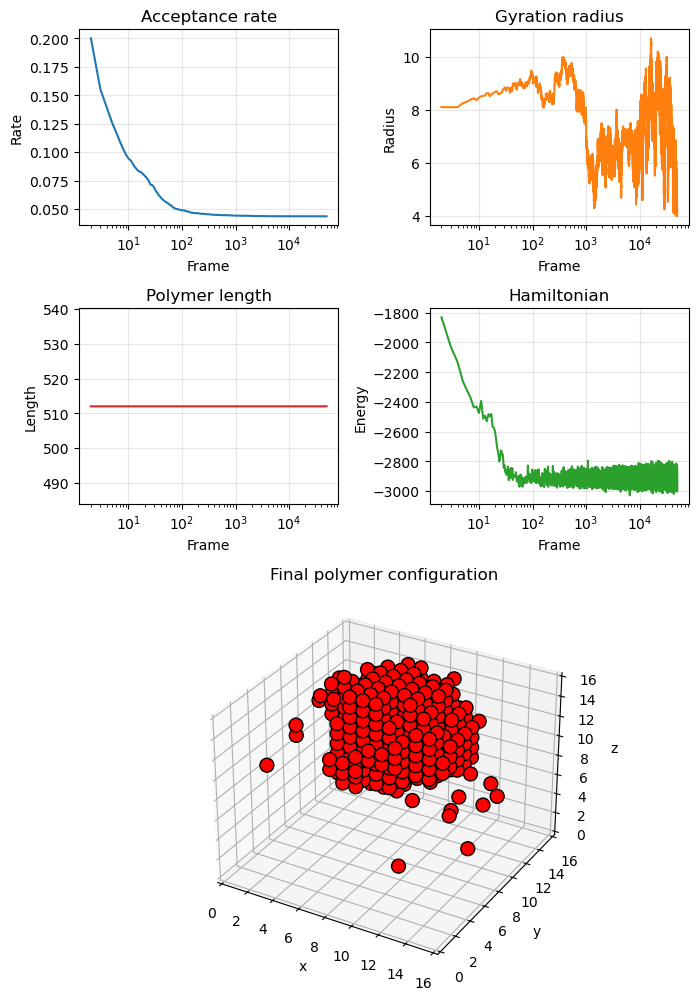

In [184]:
# Example usage:
alpha_index = 1
beta_index = 1
fig = plot_simulation_dashboard('data/20251104/bulk_phases_45m/output_cpu{}.json'.format(alpha_index), 
                                alpha_index, beta_index, psize=100)

In [180]:
out_dir = "media/figures"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "bulk_dashboard_4.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/bulk_dashboard_4.pdf


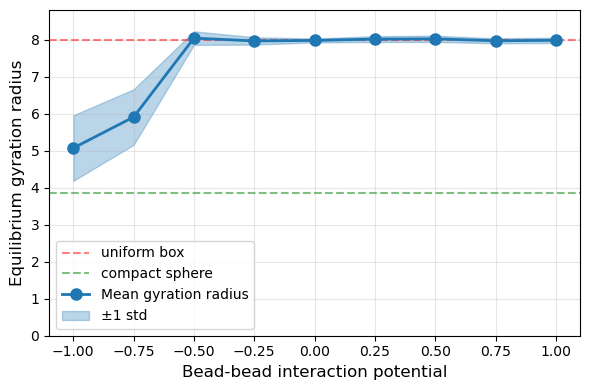

Interaction Potential → Mean Gyration Radius ± Std Dev:
  β = -1.00 → 5.070 ± 0.885 (n=5)
  β = -0.75 → 5.908 ± 0.750 (n=5)
  β = -0.50 → 8.041 ± 0.183 (n=5)
  β = -0.25 → 7.965 ± 0.100 (n=5)
  β =  0.00 → 7.977 ± 0.052 (n=5)
  β =  0.25 → 8.014 ± 0.080 (n=5)
  β =  0.50 → 8.021 ± 0.085 (n=5)
  β =  0.75 → 7.969 ± 0.068 (n=5)
  β =  1.00 → 7.981 ± 0.073 (n=5)


In [181]:
plot_order_param(data_dir = "data/20251104/bulk_phases_45m",
                 warmup = 40000, thinning = 2000)

In [182]:
out_dir = "media/figures"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "bulk_radius_gyration_vs_interaction_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/bulk_radius_gyration_vs_interaction_potential.pdf


## Droplet phase diagram

In [159]:
def plot_simulation_dashboard(res_or_path, keya, keyb, show=True, psize=30):
    """
    Plot acceptance rate, ndropation radius, Hamiltonian, polymer length vs frames,
    and a 3D scatter of the final polymer configuration.

    res_or_path: dict or path to JSON file produced by the Julia simulation.
    """
    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            res = res_[str(keya)][str(keyb)]
    else:
        res = res_or_path[str(keya)][str(keyb)]

    # Safely extract arrays
    def to_np(key):
        arr = np.array(res.get(key, []))
        return arr
    
    print("Species name: ", res["species_name"])
    print("Temperature: ", res["temperature"])
    print("Chem./int. potential: ", res["beta"])

    ndrop = to_np("ndroplets")
    ham = to_np("hamiltonian")
    acc = to_np("acceptance_rate")
    bdens = to_np("dilute_density")
    

    n = max(len(ndrop), len(ham), len(acc))
    frames = np.arange(1, n + 1)
    dsize = np.zeros(n)
    ddens = np.zeros(n)

    for i, x in enumerate(res["droplet_densities"]): 
        if x == []:
            ddens[i] = None
        else:
            ddens[i] = min(x)

    for i, x in enumerate(res["droplet_sizes"]): 
        if x == []:
            dsize[i] = None
        else:
            dsize[i] = max(x)

    fig = plt.figure(figsize=(7, 12))
    gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 2])

    # Time series
    ax_acc = fig.add_subplot(gs[0, 0])
    ax_ham = fig.add_subplot(gs[0, 1])
    ax_ndrop = fig.add_subplot(gs[1, 1])
    ax_size = fig.add_subplot(gs[1, 0])
    ax_ddens = fig.add_subplot(gs[2, 1])
    ax_bdens = fig.add_subplot(gs[2, 0])

    if len(acc):
        ax_acc.plot(frames[1:len(acc)], acc[1:], color='C0')
    ax_acc.set_title('Acceptance rate')
    ax_acc.set_xlabel('Frame')
    ax_acc.set_ylabel('Rate')
    ax_acc.grid(True, alpha=0.3)
    ax_acc.set_xscale('log')

    if len(ndrop):
        ax_ndrop.plot(frames[1:len(ndrop)], ndrop[1:], color='C1')
    ax_ndrop.set_title('Number of droplets')
    ax_ndrop.set_xlabel('Frame')
    ax_ndrop.set_ylabel('Ndroplets')
    ax_ndrop.grid(True, alpha=0.3)
    ax_ndrop.set_xscale('log')

    if len(ddens):
        ax_ddens.plot(frames[1:len(ddens)], ddens[1:], color='C4')
    ax_ddens.set_title('Droplet density')
    ax_ddens.set_xlabel('Frame')
    ax_ddens.set_ylabel('Density')
    ax_ddens.grid(True, alpha=0.3)
    ax_ddens.set_xscale('log')

    if len(bdens):
        ax_bdens.plot(frames[1:len(bdens)], bdens[1:], color='C5')
    ax_bdens.set_title('Dilute density')
    ax_bdens.set_xlabel('Frame')
    ax_bdens.set_ylabel('Density')
    ax_bdens.grid(True, alpha=0.3)
    ax_bdens.set_xscale('log')

    if len(ham):
        ax_ham.plot(frames[1:len(ham)], ham[1:], color='C2')
    ax_ham.set_title('Hamiltonian')
    ax_ham.set_xlabel('Frame')
    ax_ham.set_ylabel('Energy')
    ax_ham.grid(True, alpha=0.3)
    ax_ham.set_xscale('log')

    if len(dsize):
        ax_size.plot(frames[1:len(dsize)], dsize[1:], color='C3')
    ax_size.set_title('Max droplet size')
    ax_size.set_xlabel('Frame')
    ax_size.set_ylabel('Length')
    ax_size.grid(True, alpha=0.3)
    ax_size.set_xscale('log')

    # 3D final configuration
    ax3d = fig.add_subplot(gs[3, :], projection='3d')
    x, y, z = res["final_coordinates"]
    
    if psize > 20:
        edgecolor = "black"
    else:
        edgecolor = "none"

    ax3d.scatter(x, y, z, s=psize, c='red', marker='o', edgecolor=edgecolor, alpha=1)

    L = res.get('boxlength', None)
    if L is not None:
        ax3d.set_xlim(0, L)
        ax3d.set_ylim(0, L)
        ax3d.set_zlim(0, L)
    ax3d.set_title('Equilibrium configuration')
    ax3d.set_xlabel('x')
    ax3d.set_ylabel('y')
    ax3d.set_zlabel('z')

    plt.tight_layout()
    if show:
        plt.show()
    return fig, res

Species name:  bulk2
Temperature:  1.5
Chem./int. potential:  -1.0


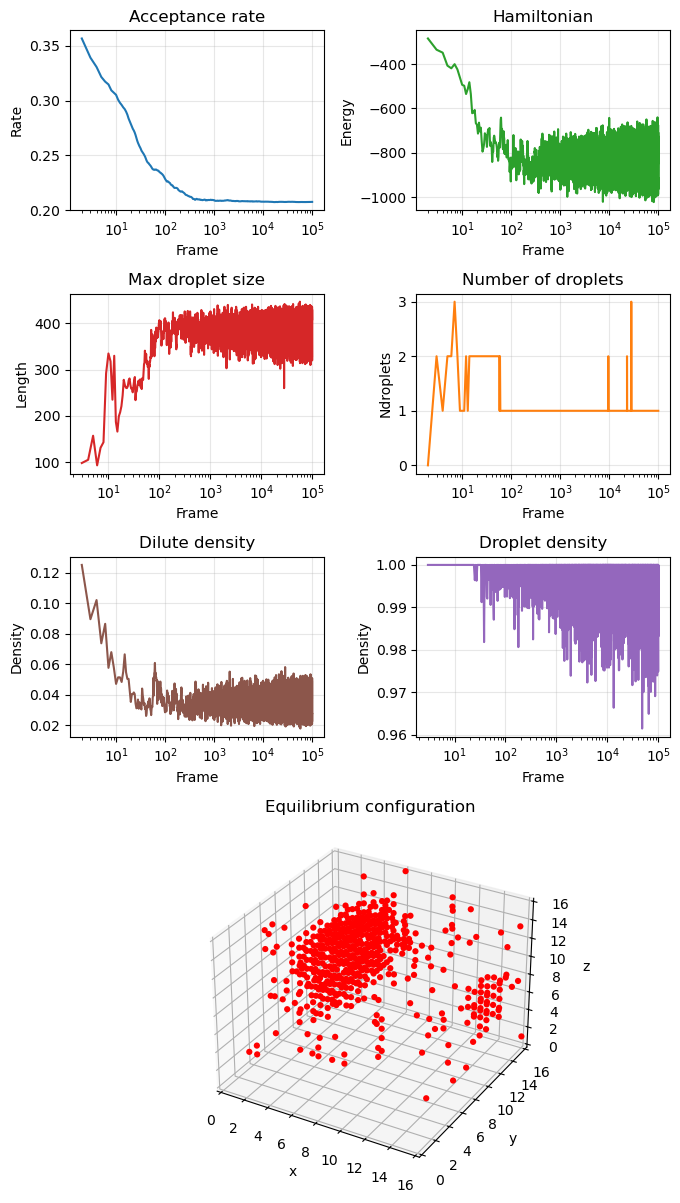

In [200]:
# Example usage:
alpha_index = 1
beta_index = 1
# dirname = "20251122/flory_huggins_spp_64_4096"
dirname = "20251126/flory_huggins_16_512"
# dirname = "20251125/flory_huggins_23_1500"
fig, data = plot_simulation_dashboard('data/{}/output_cpu{}.json'.format(dirname, alpha_index), 
                                alpha_index, beta_index, psize=20)

In [201]:
np.mean(data["dilute_density"][10000:])

0.0341333669061536

In [209]:
ddens = np.zeros(100000)

for i, x in enumerate(data["droplet_densities"]): 
    if x == []:
        ddens[i] = None
    else:
        ddens[i] = min(x)

np.nanmean(ddens[10000:])

0.9963960197161453

## Animations

#### Example

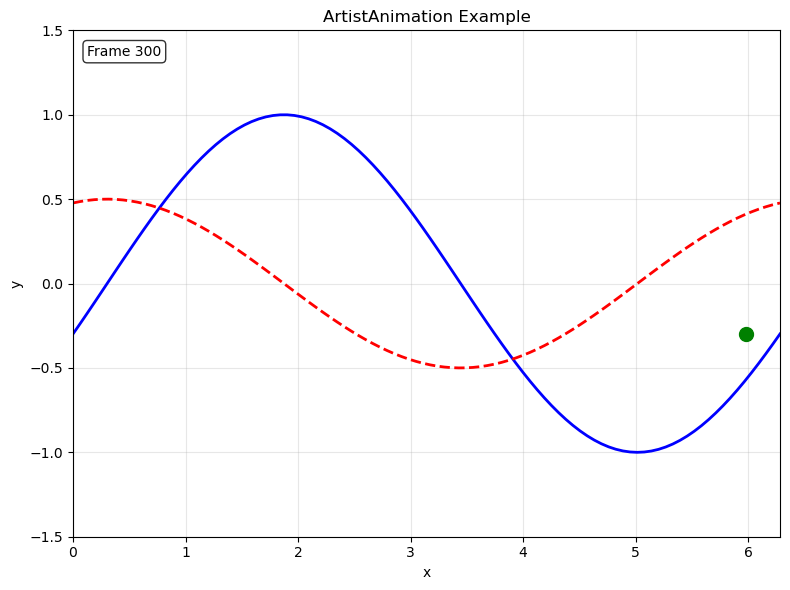

In [ ]:
# Basic example of ArtistAnimation in matplotlib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Create figure and axis
fig, ax = plt.subplots(figsize=(8, 6))

# Generate data for animation
x = np.linspace(0, 2*np.pi, 100)
frames = []

# Create a series of artists for each frame
for i in range(300):
    # Create different artists for this frame
    phase = i * 0.02
    y1 = np.sin(x + phase)
    y2 = np.cos(x + phase) * 0.5
    
    # Plot multiple elements as artists
    line1, = ax.plot(x, y1, 'b-', linewidth=2, label='sin wave')
    line2, = ax.plot(x, y2, 'r--', linewidth=2, label='cos wave')
    scatter = ax.scatter([phase], [np.sin(phase)], c='green', s=100, zorder=5)
    text = ax.text(0.02, 0.95, f'Frame {i+1}', transform=ax.transAxes, 
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # Group all artists for this frame
    frame_artists = [line1, line2, scatter, text]
    frames.append(frame_artists)

# Set up the plot
ax.set_xlim(0, 2*np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('ArtistAnimation Example')
ax.grid(True, alpha=0.3)

# Create animation
anim = animation.ArtistAnimation(fig, frames, interval=100, blit=True, repeat=True)

# Display in notebook
plt.tight_layout()

# Optional: Save as GIF (uncomment if needed)
anim.save('media/sinewaves.gif', writer='pillow', fps=25)

#### Polymer

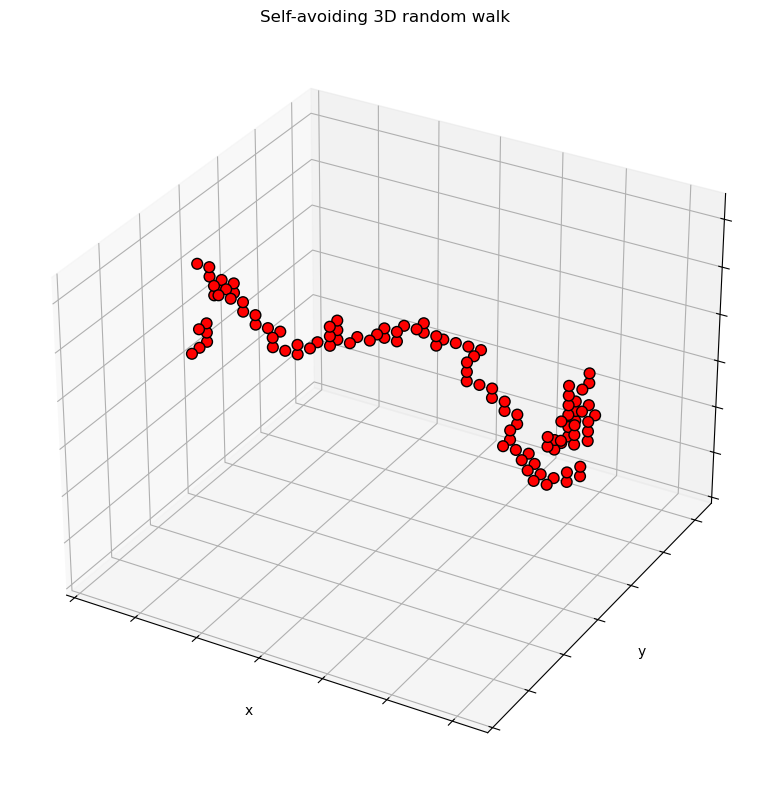

In [42]:
# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
dirname = "20251024/testpoly" 

frames = []

for i in range(2000):
    lattice = json.load(open("data/"+dirname+"_frame"+str(i+1)+".json"))
    lattice = np.array(lattice)

    # Get coordinates where array == 1
    coords = np.argwhere(lattice[..., -2] == 1)
    x, y, z = coords[:, 2], coords[:, 1], coords[:, 0]

    scatter = ax.scatter(x, y, z, s=60, c='red', marker='o', edgecolor="black", alpha=1)

    frame_artists = [scatter]
    frames.append(frame_artists)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')

# Create animation
anim = animation.ArtistAnimation(fig, frames, interval=10, 
                                 blit=True, repeat=True)

# Display in notebook
plt.tight_layout()

anim.save('media/polymer_repulsive.mp4', writer="ffmpeg", fps=25)

## Sandbox

### Flory-Huggins

In [90]:
import numdifftools as nd
from scipy import optimize as opt

###### Define basic functions

# Flory-Huggins free energy
def F(phi, *args):
    mu, chi, T = args
    return -mu*phi + 6*chi*phi**2 + T*(phi*np.log(phi) + (1-phi)*np.log(1-phi))

# Difference between F and tangent
def G(phi, *args):
    mu, chi, T, m, b = args
    return F(phi, mu, chi, T) - m*phi - b

# Its derivative
dG = nd.Derivative(G)

# Positive part of difference between line and curve
def fun(m, b, fvals, phis, beta):
    line = phis * m + b
    overshoot = (np.abs(line - fvals) + (line - fvals)) / 2

    return np.sum(line) - beta * np.sum(overshoot)

def loss(x, *args):
    m, b = x
    fvals = F(phis, *args)

    return  - fun(m, b, fvals, phis, 100)


###### Maximize area under a line, with a hard penalty on going over the F curve

# Find the tangent points: zeros of the diff's derivative
def solve_fh(phis, mu, chi, T):
    x0 = [-1, 0]
    res = opt.minimize(loss, x0, args=(mu,chi,T), method='Nelder-Mead', tol=1e-6)
    m, b = res.x

    # Evaluate it pointwise on the grid of phi values
    dGvals = np.array([dG(p, mu, chi, T, m, b) for p in phis])

    # find sign changes
    zeros = np.where(dGvals[1:] * np.roll(dGvals, 1)[1:] < 0)[0]

    # solutions
    sol = [phis[z] for z in zeros]

    if len(sol) == 3:
        return np.array([sol[0], sol[2]])
    elif len(sol) == 1:
        return np.array([sol[0]])
    else:
        print("No solutions!")
        return None


In [91]:
T = 3
mu = 1.0
chi = -1.0
eps = 5e-3
ngrid = 500
phis = np.linspace(eps, 1-eps, ngrid)

sol = solve_fh(phis, mu, chi, T)

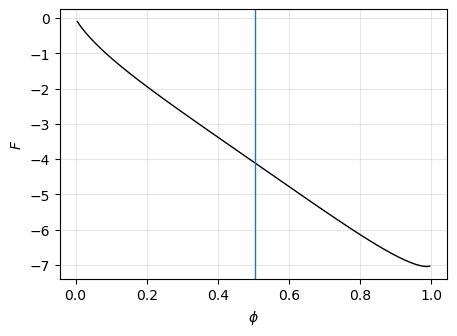

In [92]:
###### Plot

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

ax.plot(phis, F(phis, mu, chi, T), color="black", lw=1)
# ax.plot(phis, m*phis + b, lw=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$F$")
ax.grid(True, alpha=0.3)

if sol is not None:
    if len(sol) == 2:
        ax.axvline(x=sol[0], lw=1)
        ax.axvline(x=sol[1], lw=1)
    elif len(sol) == 1:
        ax.axvline(x=sol[0], lw=1)

### Phase diagram

In [ ]:
# mu = 1.0
# chi = -1.0
# eps = 5e-3
# ngrid = 500
# phis = np.linspace(eps, 1-eps, ngrid)

# Tvals = np.linspace(1.05,3, 500)
# sols = []

# for T in Tvals:
#     sol = solve_fh(phis, mu, chi, T)

#     if len(sol) == 2:
#         sols.append(sol)
#     else:
#         sols.append([None, None])

In [222]:
def to_np(key):
    arr = np.array(res.get(key, []))
    return arr

# alphas = [1,2,3,11,12,14]
alphas = np.arange(1, 17)
# dirname = "20251125/flory_huggins_23_1500"
dirname = "20251126/flory_huggins_16_512"
bdens_means = np.zeros(len(alphas))
bdens_stds = np.zeros(len(alphas))
ddens_means = np.zeros(len(alphas))
ddens_stds = np.zeros(len(alphas))

for (i, alpha) in enumerate(alphas):
    with open('data/{}/output_cpu{}.json'.format(dirname, alpha), 'r') as f:
        res_ = json.load(f)
        res = res_[str(alpha)][str(1)]

    bdens_means[i] = np.mean(to_np("dilute_density")[50000:])
    bdens_stds[i] = np.std(to_np("dilute_density")[50000:])

    ddens = np.zeros(100000)
    for j, x in enumerate(data["droplet_densities"]): 
        if x == []:
            ddens[j] = None
        else:
            ddens[j] = min(x)

    ddens_means[i] = np.nanmean(ddens[50000:])   
    ddens_stds[i] = np.nanstd(ddens[50000:])   

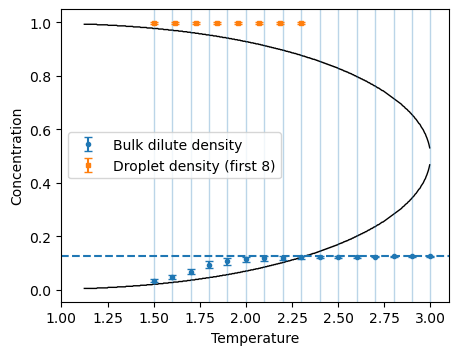

In [234]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.8))

ax.plot(Tvals, sols, color="black", lw=1)
# ax.grid(True, alpha=0.3)
ax.axhline(y=512/16**3, linestyle="dashed")
# ax.axhline(y=0.034, linestyle="dashed")
ax.set_xlabel("Temperature")
ax.set_ylabel("Concentration")

ax.set_xlim(1.0, 3.1)
for x in np.linspace(1.5, 3.0, 16):
    ax.axvline(x=x, lw = 1, alpha=0.3)

x_b = np.linspace(1.5, 3.0, 16)
x_d = np.linspace(1.5, 2.3, 8)

ax.errorbar(x_b, bdens_means, yerr=bdens_stds, fmt='o', color='C0', ecolor='C0',
            capsize=3, markersize=3, label='Bulk dilute density', zorder=10)
ax.errorbar(x_d, ddens_means[:8], yerr=ddens_stds[:8], fmt='s', color='C1', ecolor='C1',
            capsize=3, markersize=3, label='Droplet density (first 8)', zorder=11)

ax.legend()

In [235]:
fig.savefig("media/figures/20251126/fh_phase_diagram_with_simulations.pdf")

### Junkyard

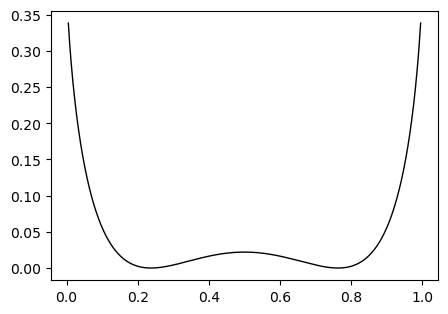

In [306]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

fs = np.abs(F_(phis) - m*phis - b)
ax.plot(phis, fs, color="black", lw=1)

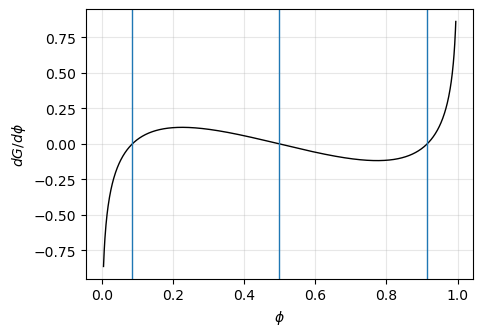

In [343]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

def G_(phi):
    return F(phi, mu, chi, T) - m*phi - b

# Numerical derivative dG/dphi using numdifftools (1D scalar argument)
dG = nd.Derivative(G_)

# Evaluate derivative pointwise on the grid of phi values and plot
dG_dphi = np.array([dG(p) for p in phis])
ax.plot(phis, dG_dphi, color="black", lw=1)

ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$dG/d\phi$")
ax.grid(True, alpha=0.3)

# find sign changes
zeros = np.where(dG_dphi[1:] * np.roll(dG_dphi, 1)[1:] < 0)[0]

if np.any(zeros):
    for z in zeros:
        ax.axvline(x=phis[z], lw=1)